Urządzenie: cpu
MSE Heurystyki (ostatnia próbka): 0.006309
Model bazowy (RNN, h=32, OKNO=30): 0.004128 ± 0.000266

================ EKSPERYMENT A (liczba jednostek) ================
Konfiguracja                 | Parametry | Test MSE (śr ± std)    | Czas [s]
---------------------------------------------------------------------------
Heurystyka (ostatnia próbka) | -         | 0.006309             | -       
GRU, hidden=8, OKNO=30       | 273       | 0.003833 ± 0.000243    | 8.79    
GRU, hidden=16, OKNO=30      | 929       | 0.003642 ± 0.000290    | 9.28    
GRU, hidden=32, OKNO=30      | 3393      | 0.003631 ± 0.000237    | 9.30    
GRU, hidden=64, OKNO=30      | 12929     | 0.003875 ± 0.000230    | 13.11   

================ EKSPERYMENT B (długość okna) ================
Konfiguracja                 | Parametry | Test MSE (śr ± std)    | Czas [s]
---------------------------------------------------------------------------
Heurystyka (ostatnia próbka) | -         | 0.006309             |

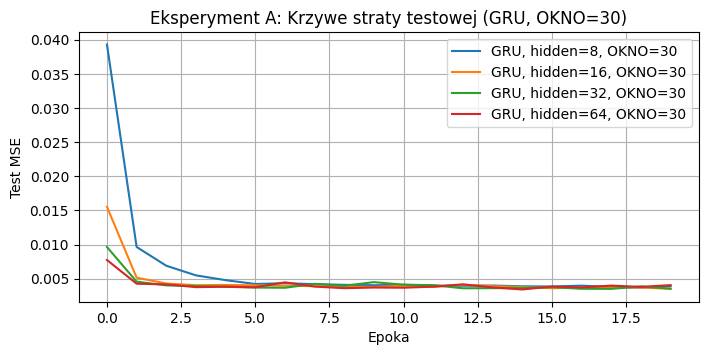

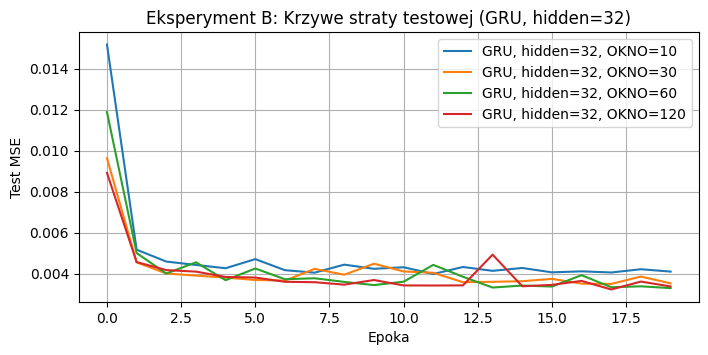

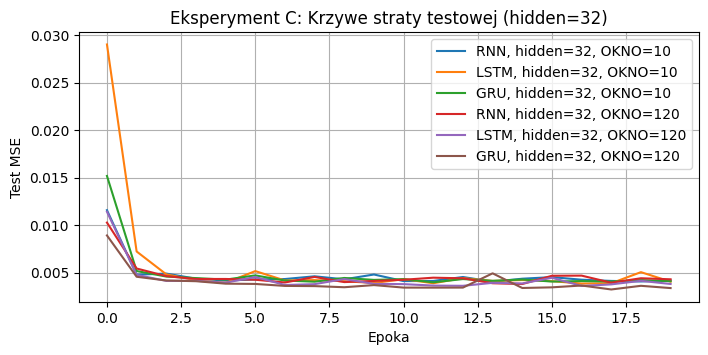

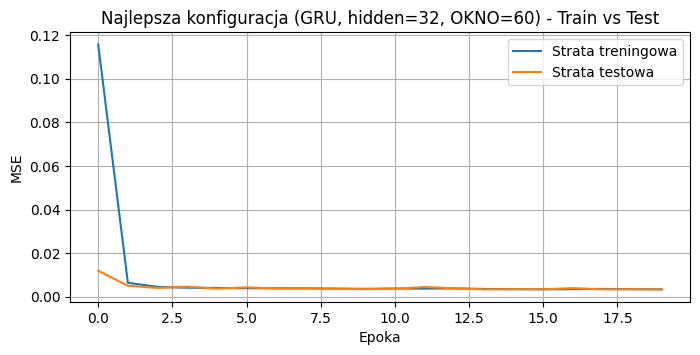

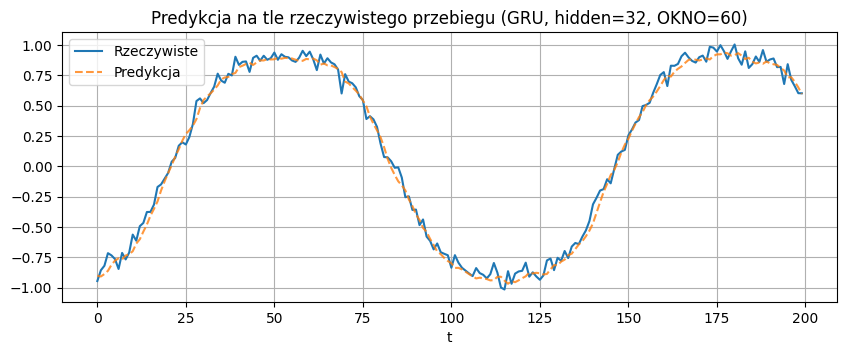

In [ ]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt


DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Urządzenie:', DEVICE)

def generuj_szereg(n=2000):
    t = np.linspace(0, 100, n)
    y = np.sin(t) + 0.1*np.sin(3*t) + 0.05*np.random.randn(n)
    return y.astype(np.float32)

def zrob_okna(seria, okno=30):
    X, Y = [], []
    for i in range(len(seria)-okno):
        X.append(seria[i:i+okno]); Y.append(seria[i+okno])
    X = np.array(X, dtype=np.float32)[..., None]
    Y = np.array(Y, dtype=np.float32)[:, None]

    n_tr = int(0.8*len(X))
    Xtr = torch.tensor(X[:n_tr]).to(DEVICE); Ytr = torch.tensor(Y[:n_tr]).to(DEVICE)
    Xte = torch.tensor(X[n_tr:]).to(DEVICE); Yte = torch.tensor(Y[n_tr:]).to(DEVICE)
    return Xtr, Ytr, Xte, Yte


class ModelRNN(nn.Module):
    def __init__(self, hidden=32, typ='RNN'):
        super().__init__()
        rnn = {'RNN': nn.RNN, 'LSTM': nn.LSTM, 'GRU': nn.GRU}[typ]
        self.rnn = rnn(input_size=1, hidden_size=hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

def policz_parametry(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def trenuj(model, Xtr, Ytr, Xte, Yte, epoki=20, lr=1e-2, batch=64):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    strata = nn.MSELoss()
    hist_tr, hist_te = [], []
    n = len(Xtr)

    for ep in range(epoki):
        model.train()
        perm = torch.randperm(n)
        loss_epoch_sum = 0.0
        b_count = 0

        for i in range(0, n, batch):
            idx = perm[i:i+batch]
            opt.zero_grad()
            loss = strata(model(Xtr[idx]), Ytr[idx])
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            loss_epoch_sum += loss.item()
            b_count += 1

        hist_tr.append(loss_epoch_sum / b_count)

        model.eval()
        with torch.no_grad():
            hist_te.append(strata(model(Xte), Yte).item())

    return hist_tr, hist_te


def uruchom_eksperyment(typ, hidden, okno, epoki=20, lr=1e-2, batch=64):
    mse_runs = []
    hist_te_runs = []
    hist_tr_runs = []
    czasy = []
    params = 0

    for seed in [0, 1, 2]:
        torch.manual_seed(seed)
        np.random.seed(seed)

        seria = generuj_szereg()
        Xtr, Ytr, Xte, Yte = zrob_okna(seria, okno)

        model = ModelRNN(hidden=hidden, typ=typ)
        params = policz_parametry(model)

        t0 = time.time()
        h_tr, h_te = trenuj(model, Xtr, Ytr, Xte, Yte, epoki=epoki, lr=lr, batch=batch)
        t1 = time.time()

        czasy.append(t1 - t0)
        hist_tr_runs.append(h_tr)
        hist_te_runs.append(h_te)

        mse_runs.append(np.mean(h_te[-5:]))

    return {
        'konfiguracja': f"{typ}, hidden={hidden}, OKNO={okno}",
        'params': params,
        'mse_mean': np.mean(mse_runs),
        'mse_std': np.std(mse_runs),
        'czas': np.mean(czasy),
        'hist_te': np.mean(hist_te_runs, axis=0),
        'hist_tr': np.mean(hist_tr_runs, axis=0),
        'ostatni_model': model,
        'Xte': Xte,
        'Yte': Yte
    }


torch.manual_seed(0); np.random.seed(0)
seria = generuj_szereg()
Xtr30, Ytr30, Xte30, Yte30 = zrob_okna(seria, okno=30)


mse_heurystyka = ((Yte30 - Xte30[:, -1])**2).mean().item()


wynik_bazowy = uruchom_eksperyment('RNN', 32, 30)

print(f"MSE Heurystyki (ostatnia próbka): {mse_heurystyka:.6f}")
print(f"Model bazowy (RNN, h=32, OKNO=30): {wynik_bazowy['mse_mean']:.6f} ± {wynik_bazowy['mse_std']:.6f}")



exp_A = [uruchom_eksperyment('GRU', h, 30) for h in [8, 16, 32, 64]]


exp_B = [uruchom_eksperyment('GRU', 32, w) for w in [10, 30, 60, 120]]


exp_C = []
for w in [10, 120]:
    for typ in ['RNN', 'LSTM', 'GRU']:
        exp_C.append(uruchom_eksperyment(typ, 32, w))



def pokaz_tabele(nazwa, wyniki):
    print(f"\n================ {nazwa} ================")
    print(f"{'Konfiguracja':<28} | {'Parametry':<9} | {'Test MSE (śr ± std)':<22} | {'Czas [s]':<8}")
    print("-" * 75)
    print(f"{'Heurystyka (ostatnia próbka)':<28} | {'-':<9} | {mse_heurystyka:.6f} {'':<11} | {'-':<8}")
    for r in wyniki:
        mse_fmt = f"{r['mse_mean']:.6f} ± {r['mse_std']:.6f}"
        print(f"{r['konfiguracja']:<28} | {r['params']:<9} | {mse_fmt:<22} | {r['czas']:<8.2f}")

pokaz_tabele("EKSPERYMENT A (liczba jednostek)", exp_A)
pokaz_tabele("EKSPERYMENT B (długość okna)", exp_B)
pokaz_tabele("EKSPERYMENT C (typ komórki)", exp_C)



plt.figure(figsize=(8, 3.5))
for r in exp_A:
    plt.plot(r['hist_te'], label=r['konfiguracja'])
plt.title('Eksperyment A: Krzywe straty testowej (GRU, OKNO=30)')
plt.xlabel('Epoka'); plt.ylabel('Test MSE'); plt.legend(); plt.grid(True); plt.show()


plt.figure(figsize=(8, 3.5))
for r in exp_B:
    plt.plot(r['hist_te'], label=r['konfiguracja'])
plt.title('Eksperyment B: Krzywe straty testowej (GRU, hidden=32)')
plt.xlabel('Epoka'); plt.ylabel('Test MSE'); plt.legend(); plt.grid(True); plt.show()


plt.figure(figsize=(8, 3.5))
for r in exp_C:
    plt.plot(r['hist_te'], label=r['konfiguracja'])
plt.title('Eksperyment C: Krzywe straty testowej (hidden=32)')
plt.xlabel('Epoka'); plt.ylabel('Test MSE'); plt.legend(); plt.grid(True); plt.show()


wszystkie = exp_A + exp_B + exp_C
najlepsza = min(wszystkie, key=lambda x: x['mse_mean'])


plt.figure(figsize=(8, 3.5))
plt.plot(najlepsza['hist_tr'], label='Strata treningowa')
plt.plot(najlepsza['hist_te'], label='Strata testowa')
plt.title(f"Najlepsza konfiguracja ({najlepsza['konfiguracja']}) - Train vs Test")
plt.xlabel('Epoka'); plt.ylabel('MSE'); plt.legend(); plt.grid(True); plt.show()


best_model = najlepsza['ostatni_model']
best_model.eval()
with torch.no_grad():
    pred = best_model(najlepsza['Xte']).cpu().numpy().ravel()
prawdziwe = najlepsza['Yte'].cpu().numpy().ravel()

plt.figure(figsize=(10, 3.5))
plt.plot(prawdziwe[:200], label='Rzeczywiste')
plt.plot(pred[:200], label='Predykcja', alpha=0.8, linestyle='--')
plt.title(f"Predykcja na tle rzeczywistego przebiegu ({najlepsza['konfiguracja']})")
plt.xlabel('t'); plt.legend(); plt.grid(True); plt.show()